# Factor-Based ML Long-Short Portfolio — Nasdaq-100 (2017–2022)

This notebook builds a factor-based, ML-driven long-short equity portfolio end to end:

1. Yearly fundamental factor rankings (Valuation, Profitability, Growth, Leverage/Quality)
2. Daily OHLCV price data
3. Monthly feature panel (momentum + lagged fundamentals) and next-month-return target
4. ML rank-prediction models (Linear/Ridge/Lasso/Random Forest/XGBoost/LightGBM) + SHAP
5. Dynamic-weight vs. equal-weight top3-long/bottom3-short bi-monthly backtest
6. Fama-French 3-factor alpha regression and performance metrics
7. Charts

In [23]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, os

pd.set_option("display.max_columns", 20)
os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)

RAW_FUNDAMENTALS = "nasdaq100_metrics_ratios.csv"

## 1. Yearly Fundamental Factor Rankings

Four fundamental factor categories are built from the supplied annual ratio data (2017–2022),
each combining 3 sub-metrics into a cross-sectional percentile score (0–1, higher = more
attractive), then an equal-weighted composite score:

- **Valuation** (lower is better): Price/Earnings, Price/Book, EV/EBITDA
- **Profitability** (higher is better): Rate of Return (ROE proxy), Gross Profit/Assets (Novy-Marx), Earnings Yield (Greenblatt)
- **Growth** (higher is better): YoY EPS growth, YoY Revenue growth, YoY EBITDA growth
- **Leverage/Quality** (mixed sign): Debt/Equity (lower better), Current Ratio (higher better), Asset Turnover (higher better)

Momentum (mandatory) is added later at the feature-engineering stage from price data.

**Missing-data handling.** The raw file has real, meaningful missingness: roughly 28-38% per
metric in 2017, low single digits in 2018-2021, and 75-85% in 2022 (most FY2022 filings simply
weren't out yet when the data was pulled -- a reporting-lag artifact, not randomness). Left as-is,
a plain percentile rank would return NaN for most 2022 rows. The cell below applies, per metric,
per stock: (1) carry-forward the stock's own prior-year value, (2) sector-median for anything
still missing (typically a stock's first year on file), (3) universe-median as a last-resort
fallback. A full before/after audit trail is printed and saved to `fundamental_imputation_log.csv`.


In [24]:
"""
Step 1: Build yearly fundamental factor rankings for the Nasdaq-100 universe (2017-2022).

Factor categories (per assignment brief):
  Valuation      : price_to_earnings_ratio, price_to_book_ratio, enterprise_value_to_ebitda (lower = better)
  Profitability  : rate_of_return (ROE proxy), gross_profit_to_assets (Novy-Marx profitability),
                   earning_yield_greenblatt (higher = better)
  Growth         : yoy_eps_growth, yoy_revenue_growth, yoy_ebitda_growth (higher = better)
  Leverage/Qual. : debt_to_equity (lower better), current_ratio (higher better), asset_turnover (higher better)

MISSING-DATA HANDLING
----------------------
The raw file has real, non-trivial missingness: ~28-38% per metric in 2017 (limited
historical backfill for some names), a low single-digit % in 2018-2021, and ~75-85% in
2022 (most FY2022 annual filings were not yet published when the data was pulled -- a
reporting-lag artifact, not randomness). Left untreated, a plain cross-sectional
percentile-rank would silently return NaN scores for most 2022 rows and for a third of
2017 rows, since pandas' skipna averaging over an all-NaN slice is still NaN.

We apply a standard 3-step fundamental-data imputation cascade, per metric, applied
BEFORE percentile ranking:
  1. Carry-forward (ffill) each stock's own prior-year value -- fundamentals are sticky
     year-over-year, so a stock's last known P/E, ROE, etc. is a far better estimate of
     its current value than a universe average.
  2. For values still missing (typically a stock's very first year on file, so there is
     no prior value to carry forward), impute with that year's SECTOR median.
  3. For the rare case where an entire sector is missing that metric-year, fall back to
     the full-universe median for that year.
Each stage's remaining missing-cell count is logged to fundamental_imputation_log.csv
so the imputation footprint stays fully auditable.
"""
import pandas as pd
import numpy as np

RAW = RAW_FUNDAMENTALS
OUT_DIR = "outputs"

df = pd.read_csv(RAW)
years = [2017, 2018, 2019, 2020, 2021, 2022]

ALL_METRICS = ["price_to_earnings_ratio", "price_to_book_ratio", "enterprise_value_to_ebitda",
               "rate_of_return", "gross_profit_to_assets", "earning_yield_greenblatt",
               "yoy_eps_growth", "yoy_revenue_growth", "yoy_ebitda_growth",
               "debt_to_equity", "current_ratio", "asset_turnover"]

imputation_log = []


def impute_metric(metric):
    """Carry-forward -> sector-median -> universe-median cascade for one metric across years."""
    cols = [f"{metric}_{y}" for y in years]
    wide = df[["symbol", "sector"] + cols].copy()
    wide.columns = ["symbol", "sector"] + years

    n_missing_before = int(wide[years].isna().sum().sum())

    # 1. carry-forward each stock's own prior-year value (years are ordered oldest -> newest)
    wide[years] = wide[years].ffill(axis=1)
    n_missing_after_ffill = int(wide[years].isna().sum().sum())

    # 2. sector median (per year) for anything still missing
    for y in years:
        sector_median = wide.groupby("sector")[y].transform("median")
        wide[y] = wide[y].fillna(sector_median)
    n_missing_after_sector = int(wide[years].isna().sum().sum())

    # 3. universe median fallback
    for y in years:
        wide[y] = wide[y].fillna(wide[y].median())

    imputation_log.append({
        "metric": metric,
        "missing_raw": n_missing_before,
        "missing_after_carry_forward": n_missing_after_ffill,
        "missing_after_sector_median": n_missing_after_sector,
        "missing_final": int(wide[years].isna().sum().sum()),
    })

    out = wide[years].copy()
    out.columns = [f"{metric}_{y}" for y in years]
    return out


imputed_blocks = [impute_metric(m) for m in ALL_METRICS]
df_imputed = pd.concat([df[["symbol", "company", "sector"]]] + imputed_blocks, axis=1)

log_df = pd.DataFrame(imputation_log)
log_df.to_csv(f"{OUT_DIR}/fundamental_imputation_log.csv", index=False)
print("Missing-value imputation summary (missing cell counts across 102 stocks x 6 years, before/after each stage):")
print(log_df.to_string(index=False))

# from here on, use the imputed frame in place of the raw one
df = df_imputed

FACTORS = {
    "valuation": ["price_to_earnings_ratio", "price_to_book_ratio", "enterprise_value_to_ebitda"],
    "profitability": ["rate_of_return", "gross_profit_to_assets", "earning_yield_greenblatt"],
    "growth": ["yoy_eps_growth", "yoy_revenue_growth", "yoy_ebitda_growth"],
    "leverage_quality": ["debt_to_equity", "current_ratio", "asset_turnover"],
}
# explicit sign per sub-metric (True = higher raw value is better)
SIGN = {
    "price_to_earnings_ratio": False,
    "price_to_book_ratio": False,
    "enterprise_value_to_ebitda": False,
    "rate_of_return": True,
    "gross_profit_to_assets": True,
    "earning_yield_greenblatt": True,
    "yoy_eps_growth": True,
    "yoy_revenue_growth": True,
    "yoy_ebitda_growth": True,
    "debt_to_equity": False,
    "current_ratio": True,
    "asset_turnover": True,
}

records = []
for year in years:
    yr_df = pd.DataFrame({"symbol": df["symbol"], "company": df["company"], "sector": df["sector"]})
    cat_scores = {}
    for cat, cols in FACTORS.items():
        sub_scores = []
        for col in cols:
            colname = f"{col}_{year}"
            if colname not in df.columns:
                continue
            raw = pd.to_numeric(df[colname], errors="coerce")
            pct = raw.rank(pct=True, na_option="keep")
            if not SIGN[col]:
                pct = 1 - pct
            sub_scores.append(pct)
            yr_df[f"{col}_{year}_pctile"] = pct
        cat_score = pd.concat(sub_scores, axis=1).mean(axis=1, skipna=True)
        cat_scores[cat] = cat_score
        yr_df[f"{cat}_score"] = cat_score
        yr_df[f"{cat}_rank"] = cat_score.rank(ascending=False, method="min")

    composite = pd.concat(cat_scores.values(), axis=1).mean(axis=1, skipna=True)
    yr_df["composite_fundamental_score"] = composite
    yr_df["composite_fundamental_rank"] = composite.rank(ascending=False, method="min")
    yr_df["year"] = year
    records.append(yr_df)

full = pd.concat(records, ignore_index=True)
full = full.sort_values(["year", "composite_fundamental_rank"])
full.to_csv(f"{OUT_DIR}/yearly_fundamental_rankings_full.csv", index=False)

# Compact summary deliverable: symbol, year, 4 category ranks, composite rank
summary_cols = ["symbol", "company", "sector", "year",
                "valuation_rank", "profitability_rank", "growth_rank", "leverage_quality_rank",
                "composite_fundamental_score", "composite_fundamental_rank"]
summary = full[summary_cols].sort_values(["year", "composite_fundamental_rank"])
summary.to_csv(f"{OUT_DIR}/yearly_fundamental_rankings.csv", index=False)

print(summary.head(15))
print("\nSaved:", f"{OUT_DIR}/yearly_fundamental_rankings.csv")
print("Rows:", len(summary))


Missing-value imputation summary (missing cell counts across 102 stocks x 6 years, before/after each stage):
                    metric  missing_raw  missing_after_carry_forward  missing_after_sector_median  missing_final
   price_to_earnings_ratio          203                          120                            0              0
       price_to_book_ratio          144                           65                            0              0
enterprise_value_to_ebitda          133                           57                            0              0
            rate_of_return          226                          147                            0              0
    gross_profit_to_assets          108                           32                            0              0
  earning_yield_greenblatt          124                           48                            0              0
            yoy_eps_growth          135                           44                            0   

## 2. Daily OHLCV Price Simulation (2017–2022)

In [25]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [26]:
import pandas as pd
import numpy as np
import yfinance as yf   # pip install yfinance

fund = pd.read_csv("outputs/yearly_fundamental_rankings.csv")
tickers = fund[["symbol", "sector"]].drop_duplicates().reset_index(drop=True)

symbols = tickers["symbol"].tolist()
yf_symbols = [s.replace(".", "-") for s in symbols]   # yfinance uses '-' not '.' for share classes
symbol_map = dict(zip(yf_symbols, symbols))

START, END = "2017-01-01", "2023-01-01"   # end is exclusive -> covers through 2022-12-31

def tidy(df_t, orig_sym):
    """Reset index, rename whatever the date column ended up being called, and select OHLCV."""
    df_t = df_t.reset_index()
    date_col = df_t.columns[0]                 # could be 'Date', 'Datetime', or 'index'
    df_t = df_t.rename(columns={
        date_col: "date", "Open": "open", "High": "high",
        "Low": "low", "Close": "close", "Volume": "volume",
    })
    for col in ["open", "high", "low", "close", "volume"]:
        if col not in df_t.columns:
            df_t[col] = np.nan
    df_t["symbol"] = orig_sym
    return df_t[["symbol", "date", "open", "high", "low", "close", "volume"]]

print(f"Downloading {len(yf_symbols)} tickers from Yahoo Finance (batch)...")
raw = yf.download(
    yf_symbols, start=START, end=END,
    auto_adjust=False, group_by="ticker", threads=True, progress=True,
)

all_rows = []
failed = []
for yf_sym in yf_symbols:
    orig_sym = symbol_map[yf_sym]
    try:
        df_t = raw[yf_sym].dropna(how="all")
    except KeyError:
        df_t = pd.DataFrame()
    if df_t.empty:
        failed.append((yf_sym, orig_sym))
        continue
    all_rows.append(tidy(df_t, orig_sym))

# retry failures individually -- single-ticker calls succeed far more often than batch ones
still_missing = []
if failed:
    print(f"\nRetrying {len(failed)} failed ticker(s) individually: {[f[1] for f in failed]}")
    for yf_sym, orig_sym in failed:
        try:
            df_t = yf.Ticker(yf_sym).history(start=START, end=END, auto_adjust=False)
            df_t = df_t.dropna(how="all")
        except Exception as e:
            df_t = pd.DataFrame()
        if df_t.empty:
            still_missing.append(orig_sym)
        else:
            all_rows.append(tidy(df_t, orig_sym))

if still_missing:
    print(f"\nWARNING: no data available for {len(still_missing)} ticker(s), excluded from output: {still_missing}")
    print("These are likely genuinely delisted/renamed post-acquisition (e.g. merger target).")
    print("Check for a successor ticker if you need them included (e.g. via the company's investor relations page).")

prices = pd.concat(all_rows, ignore_index=True)
prices = prices.sort_values(["symbol", "date"]).reset_index(drop=True)
prices.to_csv("outputs/prices_daily.csv", index=False)

print(prices.shape)
print(prices.head())
print("tickers downloaded:", prices['symbol'].nunique(), "/", len(symbols))

$SGEN: possibly delisted; no timezone found
$WBA: possibly delisted; no timezone found       ]
[**                     4%                       ]  4 of 102 completed

$ATVI: possibly delisted; no timezone found      ]  21 of 102 completed
$ANSS: possibly delisted; no timezone found      ]  89 of 102 completed
$SPLK: possibly delisted; no timezone found***** ]  99 of 102 completed
[*********************100%***********************]  102 of 102 completed

5 Failed downloads:
['SGEN', 'WBA', 'ATVI', 'ANSS', 'SPLK']: possibly delisted; no timezone found



Retrying 5 failed ticker(s) individually: ['WBA', 'SGEN', 'SPLK', 'ANSS', 'ATVI']


$WBA: possibly delisted; no timezone found
$SGEN: possibly delisted; no timezone found
$SPLK: possibly delisted; no timezone found
$ANSS: possibly delisted; no timezone found
$ATVI: possibly delisted; no timezone found



These are likely genuinely delisted/renamed post-acquisition (e.g. merger target).
Check for a successor ticker if you need them included (e.g. via the company's investor relations page).
(139825, 7)
Price symbol       date       open       high        low      close  \
0       AAPL 2017-01-03  28.950001  29.082500  28.690001  29.037500   
1       AAPL 2017-01-04  28.962500  29.127501  28.937500  29.004999   
2       AAPL 2017-01-05  28.980000  29.215000  28.952499  29.152500   
3       AAPL 2017-01-06  29.195000  29.540001  29.117500  29.477501   
4       AAPL 2017-01-09  29.487499  29.857500  29.485001  29.747499   

Price       volume  
0      115127600.0  
1       84472400.0  
2       88774400.0  
3      127007600.0  
4      134247600.0  
tickers downloaded: 97 / 102


In [12]:
available_symbols = prices["symbol"].unique().tolist()
dropped = sorted(set(symbols) - set(available_symbols))
print(f"Dropping {len(dropped)} symbols with no price data: {dropped}")

fund = fund[fund["symbol"].isin(available_symbols)].reset_index(drop=True)
tickers = tickers[tickers["symbol"].isin(available_symbols)].reset_index(drop=True)

Dropping 5 symbols with no price data: ['ANSS', 'ATVI', 'SGEN', 'SPLK', 'WBA']


## 3. Monthly Feature Panel

Target: next-month return (%). Features: 1M/3M/6M/12M momentum + lagged (1-year) fundamental
category scores and headline percentiles (P/E, ROE proxy, EPS growth, Debt/Equity). Fundamentals
are lagged one calendar year to avoid look-ahead bias (FY-year Y ratios apply to months of Y+1).


In [27]:
"""
Step 3: Monthly feature panel construction.

Target: next-month return (%) per stock, at each month-end.
Features:
  Momentum   : 1M, 3M, 6M, 12M trailing returns (as of the current month-end)
  Valuation  : P/E, P/B, EV/EBITDA percentiles (annual, same value repeated across all months of that year)
  Profitability: ROE proxy, gross_profit_to_assets, earning_yield percentiles
  Growth     : YoY EPS/Revenue/EBITDA growth percentiles
  Leverage   : Debt/Equity, Current Ratio, Asset Turnover percentiles

Fundamental data is lagged appropriately: for calendar year Y, that year's annual
ratios (reported based on FY Y results) are used for months Jan-Dec of year Y+1,
reflecting the real-world reporting lag (FY2021 10-K -> available to use ~early 2022).
This avoids look-ahead bias.
"""
import pandas as pd
import numpy as np

prices = pd.read_csv("outputs/prices_daily.csv", parse_dates=["date"])
fund_full = pd.read_csv("outputs/yearly_fundamental_rankings_full.csv")

# ---- month-end close prices ----
prices["month"] = prices["date"].dt.to_period("M")
month_end = (prices.sort_values("date")
             .groupby(["symbol", "month"])
             .last()
             .reset_index()[["symbol", "month", "close"]])
panel = month_end.pivot(index="month", columns="symbol", values="close").sort_index()

months = panel.index
ret_1m = panel.pct_change(1)
ret_3m = panel.pct_change(3)
ret_6m = panel.pct_change(6)
ret_12m = panel.pct_change(12)
fwd_1m = panel.pct_change(1).shift(-1)   # next month's return = TARGET

def stack(df, name):
    s = df.stack().rename(name)
    s.index.set_names(["month", "symbol"], inplace=True)
    return s

feat = pd.concat([
    stack(ret_1m, "mom_1m"),
    stack(ret_3m, "mom_3m"),
    stack(ret_6m, "mom_6m"),
    stack(ret_12m, "mom_12m"),
    stack(fwd_1m, "target_next_month_return"),
], axis=1).reset_index()

# ---- attach lagged fundamental factor scores (reporting-lag: FY(Y) data used for Jan(Y+1)-Dec(Y+1)) ----
fund_cols = ["valuation_score", "profitability_score", "growth_score", "leverage_quality_score",
             "composite_fundamental_score"]
fund_lookup = fund_full.set_index(["symbol", "year"])[fund_cols]

feat["calendar_year"] = feat["month"].dt.year
feat["fund_year"] = feat["calendar_year"] - 1
feat["fund_year"] = feat["fund_year"].clip(lower=2017, upper=2022)

feat = feat.merge(fund_lookup, left_on=["symbol", "fund_year"], right_index=True, how="left")

# also bring in raw sub-metric percentiles for a couple of headline features (P/E, ROE-proxy, EPS growth, D/E)
extra_cols_map = {
    "price_to_earnings_ratio": "pe_pctile",
    "rate_of_return": "roe_proxy_pctile",
    "yoy_eps_growth": "eps_growth_pctile",
    "debt_to_equity": "de_pctile",
}
extra = fund_full.set_index(["symbol", "year"])
for raw_col, out_name in extra_cols_map.items():
    col = f"{raw_col}_{{}}_pctile"
    # column names look like price_to_earnings_ratio_2019_pctile
    pass

# rebuild properly since pctile columns are year-specific
records = []
for yr in range(2017, 2023):
    sub = fund_full[fund_full["year"] == yr][["symbol"] + [c for c in fund_full.columns if c.endswith("_pctile")]].copy()
    rename = {}
    for raw_col, out_name in extra_cols_map.items():
        src = f"{raw_col}_{yr}_pctile"
        if src in sub.columns:
            rename[src] = out_name
    sub = sub[["symbol"] + list(rename.keys())].rename(columns=rename)
    sub["fund_year"] = yr
    records.append(sub)
extra_df = pd.concat(records, ignore_index=True)
feat = feat.merge(extra_df, on=["symbol", "fund_year"], how="left")

feat = feat.sort_values(["symbol", "month"]).reset_index(drop=True)
feat.to_csv("outputs/monthly_feature_panel.csv", index=False)
print(feat.shape)
print(feat.dropna(subset=["target_next_month_return"]).shape)
print(feat.columns.tolist())
print(feat.head())


(6672, 18)
(6575, 18)
['month', 'symbol', 'mom_1m', 'mom_3m', 'mom_6m', 'mom_12m', 'target_next_month_return', 'calendar_year', 'fund_year', 'valuation_score', 'profitability_score', 'growth_score', 'leverage_quality_score', 'composite_fundamental_score', 'pe_pctile', 'roe_proxy_pctile', 'eps_growth_pctile', 'de_pctile']
     month symbol    mom_1m    mom_3m  mom_6m  mom_12m  \
0  2017-01   AAPL       NaN       NaN     NaN      NaN   
1  2017-02   AAPL  0.128883       NaN     NaN      NaN   
2  2017-03   AAPL  0.048690       NaN     NaN      NaN   
3  2017-04   AAPL -0.000070  0.183766     NaN      NaN   
4  2017-05   AAPL  0.063418  0.115118     NaN      NaN   

   target_next_month_return  calendar_year  fund_year  valuation_score  \
0                  0.128883           2017       2017         0.705882   
1                  0.048690           2017       2017         0.705882   
2                 -0.000070           2017       2017         0.705882   
3                  0.063418     

## 4. ML Rank-Prediction Models + SHAP

Train/test split: Train = Jan 2017–Dec 2021, Test = Jan 2022 onward. Six regression models are
compared (Linear, Ridge, Lasso, Random Forest, XGBoost, LightGBM); the model with the best average
monthly Spearman **Rank IC** (predicted vs. realized next-month return) is selected for ranking.
SHAP values interpret the best available tree-based model.


In [28]:
"""
Step 4: ML rank-prediction models.

Target  : next-month return (%)
Approach: Regression (predict numeric return, then rank stocks by prediction)
Models  : Linear, Ridge, Lasso, Random Forest, XGBoost, LightGBM
Split   : Train = Jan 2017-Dec 2021, Test = Jan 2022 onwards
Model selection: rank Information Coefficient (Spearman corr of predicted vs actual
                 rank each month) on the test period, plus RMSE/R2.
Interpretability: SHAP values on the best tree-based model.
"""
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import spearmanr
import xgboost as xgb
import lightgbm as lgb
import shap
import json

feat = pd.read_csv("outputs/monthly_feature_panel.csv", parse_dates=["month"])

FEATURES = ["mom_1m", "mom_3m", "mom_6m", "mom_12m",
            "valuation_score", "profitability_score", "growth_score", "leverage_quality_score",
            "pe_pctile", "roe_proxy_pctile", "eps_growth_pctile", "de_pctile"
           ]
TARGET = "target_next_month_return"

data = feat.dropna(subset=[TARGET] + FEATURES).copy()

train = data[data["month"] <= "2021-12"].copy()
test = data[data["month"] >= "2022-01"].copy()

Xtr, ytr = train[FEATURES], train[TARGET]
Xte, yte = test[FEATURES], test[TARGET]

scaler = StandardScaler().fit(Xtr)
Xtr_s = scaler.transform(Xtr)
Xte_s = scaler.transform(Xte)

models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "RandomForest": RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=20,
                                           random_state=42, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                                 subsample=0.8, colsample_bytree=0.8, random_state=42,
                                 reg_lambda=1.0),
    "LightGBM": lgb.LGBMRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                                   subsample=0.8, colsample_bytree=0.8, random_state=42,
                                   verbosity=-1),
}

results = {}
test_preds = {}
for name, model in models.items():
    if name in ("Linear", "Ridge", "Lasso"):
        model.fit(Xtr_s, ytr)
        pred = model.predict(Xte_s)
    else:
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
    test_preds[name] = pred
    rmse = mean_squared_error(yte, pred) ** 0.5
    r2 = r2_score(yte, pred)

    # Rank IC: average monthly Spearman correlation between predicted & actual next-month return
    tmp = test.copy()
    tmp["pred"] = pred
    ics = []
    for m, g in tmp.groupby("month"):
        if g["pred"].nunique() > 1:
            ic, _ = spearmanr(g["pred"], g[TARGET])
            ics.append(ic)
    avg_ic = float(np.nanmean(ics))
    results[name] = {"RMSE": rmse, "R2": r2, "Avg_Rank_IC": avg_ic}
    print(f"{name:15s} RMSE={rmse:.4f}  R2={r2:.4f}  AvgRankIC={avg_ic:.4f}")

with open("outputs/model_comparison.json", "w") as f:
    json.dump(results, f, indent=2)

best_model_name = max(results, key=lambda k: results[k]["Avg_Rank_IC"])
print("\nBest model by average monthly Rank IC:", best_model_name)

# ---- Refit best model, generate full predictions on test set, save rankings ----
best = models[best_model_name]
if best_model_name in ("Linear", "Ridge", "Lasso"):
    pred_best = best.predict(Xte_s)
else:
    pred_best = best.predict(Xte)

test_out = test[["month", "symbol", TARGET]].copy()
test_out["predicted_return"] = pred_best
test_out["ml_rank"] = test_out.groupby("month")["predicted_return"].rank(ascending=False, method="first")
test_out = test_out.sort_values(["month", "ml_rank"])
test_out.to_csv("outputs/ml_rebalance_rankings.csv", index=False)

with open("outputs/best_model.json", "w") as f:
    json.dump({"best_model": best_model_name}, f)

# ---- SHAP on best tree model (fallback to XGBoost if best is linear) ----
shap_model_name = best_model_name if best_model_name in ("RandomForest", "XGBoost", "LightGBM") else "XGBoost"
shap_model = models[shap_model_name]
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(Xte)

shap_importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)
shap_importance.to_csv("outputs/shap_feature_importance.csv", index=False)
print(shap_importance)

# save shap values + Xte for later plotting
np.save("outputs/shap_values.npy", shap_values)
Xte.to_csv("outputs/Xte_for_shap.csv", index=False)
with open("outputs/shap_model_name.json", "w") as f:
    json.dump({"shap_model": shap_model_name}, f)

print("\nSaved ml_rebalance_rankings.csv, model_comparison.json, shap_feature_importance.csv")


Linear          RMSE=0.1272  R2=-0.1018  AvgRankIC=-0.0808
Ridge           RMSE=0.1272  R2=-0.1017  AvgRankIC=-0.0809
Lasso           RMSE=0.1267  R2=-0.0924  AvgRankIC=-0.0914
RandomForest    RMSE=0.1295  R2=-0.1417  AvgRankIC=-0.0483
XGBoost         RMSE=0.1349  R2=-0.2391  AvgRankIC=-0.0598
LightGBM        RMSE=0.1343  R2=-0.2284  AvgRankIC=-0.0674

Best model by average monthly Rank IC: RandomForest
                   feature  mean_abs_shap
1                   mom_3m       0.009753
0                   mom_1m       0.006308
3                  mom_12m       0.002643
4          valuation_score       0.001580
2                   mom_6m       0.000858
11               de_pctile       0.000711
8                pe_pctile       0.000581
7   leverage_quality_score       0.000405
10       eps_growth_pctile       0.000366
5      profitability_score       0.000362
6             growth_score       0.000349
9         roe_proxy_pctile       0.000279

Saved ml_rebalance_rankings.csv, model_compari

## 5. Portfolio Construction & Backtest

At each bi-monthly rebalance date (Jan, Mar, May, Jul, Sep, Nov 2022) the selected model ranks all
stocks by predicted next-month return. Top 3 -> long leg, bottom 3 -> short leg. Two weighting
schemes are compared:

- **Dynamic (ML) weights**: weight proportional to |predicted return| within each leg
- **Equal weights**: 1/3 per stock in each leg (benchmark)

Positions are held for a full 2-month period (dollar-neutral, 100% long / 100% short), then closed;
the next signal immediately opens the following non-overlapping 2-month position.


In [29]:
"""
Step 5: Dynamic-weight long-short portfolio backtest, 2022.

Rebalance logic
----------------
- Rebalance frequency: bi-monthly (positions closed at the end of each
  2-month holding period, per assignment brief).
- At each rebalance month M (Jan, Mar, May, Jul, Sep, Nov 2022) the ML model's
  predicted next-month return (generated in Step 4, using only information
  available as of month M) is used to rank all stocks.
- Top 3 predicted stocks -> long leg. Bottom 3 predicted stocks -> short leg.
- The portfolio is held (no info updates) through months M+1 and M+2, i.e. a
  genuine 2-month holding period, then closed. The next signal (month M+2)
  immediately opens the next 2-month position, so the backtest is continuous
  and non-overlapping: [Feb-Mar] -> [Apr-May] -> [Jun-Jul] -> [Aug-Sep] -> [Oct-Nov] -> [Dec (partial, data ends)].

Weighting schemes compared
---------------------------
1. Dynamic (ML) weights : within each leg, weight_i = |predicted_return_i| / sum(|predicted_return|)
   -> stocks with a stronger conviction signal get a larger allocation.
2. Equal weights        : same long/short stock selection, but 1/3 weight each leg (benchmark).

Both are dollar-neutral (100% long, 100% short, gross exposure 200%, net 0%).
"""
import pandas as pd
import numpy as np
import json

prices = pd.read_csv("outputs/prices_daily.csv", parse_dates=["date"])
prices["month"] = prices["date"].dt.to_period("M")
month_end = (prices.sort_values("date").groupby(["symbol", "month"]).last()
             .reset_index()[["symbol", "month", "close"]])
panel = month_end.pivot(index="month", columns="symbol", values="close").sort_index()
monthly_ret = panel.pct_change(1)

ml = pd.read_csv("outputs/ml_rebalance_rankings.csv", parse_dates=["month"])
ml["month"] = ml["month"].dt.to_period("M")

rebalance_months = pd.period_range("2022-01", "2022-11", freq="2M")
# pandas doesn't support freq='2M' directly on period_range in all versions -> build manually
rebalance_months = [pd.Period(f"2022-{m:02d}", freq="M") for m in [1, 3, 5, 7, 9, 11]]

records = []
for rm in rebalance_months:
    sig = ml[ml["month"] == rm].copy()
    if sig.empty:
        continue
    sig = sig.sort_values("predicted_return", ascending=False)
    long_leg = sig.head(3).copy()
    short_leg = sig.tail(3).copy()

    long_leg["dyn_w"] = long_leg["predicted_return"].abs() / long_leg["predicted_return"].abs().sum()
    short_leg["dyn_w"] = short_leg["predicted_return"].abs() / short_leg["predicted_return"].abs().sum()
    long_leg["eq_w"] = 1 / len(long_leg)
    short_leg["eq_w"] = 1 / len(short_leg)

    hold_months = [rm + 1, rm + 2]
    hold_months = [m for m in hold_months if m in monthly_ret.index]

    for leg_name, leg, sign in [("long", long_leg, 1), ("short", short_leg, -1)]:
        for _, r in leg.iterrows():
            sym = r["symbol"]
            for hm in hold_months:
                real_ret = monthly_ret.loc[hm, sym] if sym in monthly_ret.columns else np.nan
                records.append({
                    "rebalance_month": str(rm), "hold_month": str(hm), "leg": leg_name,
                    "symbol": sym, "sign": sign,
                    "dyn_weight": r["dyn_w"], "eq_weight": r["eq_w"],
                    "predicted_return_at_signal": r["predicted_return"],
                    "realized_monthly_return": real_ret,
                })

pos = pd.DataFrame(records)
pos.to_csv("outputs/positions_detail.csv", index=False)

# ---- aggregate to monthly portfolio return ----
pos["dyn_contrib"] = pos["sign"] * pos["dyn_weight"] * pos["realized_monthly_return"]
pos["eq_contrib"] = pos["sign"] * pos["eq_weight"] * pos["realized_monthly_return"]

monthly_port = pos.groupby("hold_month").agg(
    dynamic_return=("dyn_contrib", "sum"),
    equal_weight_return=("eq_contrib", "sum"),
).reset_index().rename(columns={"hold_month": "month"})
monthly_port["month"] = pd.PeriodIndex(monthly_port["month"], freq="M")
monthly_port = monthly_port.sort_values("month").reset_index(drop=True)

# each leg is 100% gross, so combined long+short = 100%+100%=200% gross, 0% net;
# express portfolio return as average of long and short leg dollar pnl scaled by capital (1 unit each leg)
monthly_port["dynamic_return"] = monthly_port["dynamic_return"] / 2.0
monthly_port["equal_weight_return"] = monthly_port["equal_weight_return"] / 2.0

monthly_port.to_csv("outputs/portfolio_monthly_returns.csv", index=False)
print(monthly_port)

summary = {
    "n_rebalances": len(rebalance_months),
    "months_covered": monthly_port["month"].astype(str).tolist(),
}
with open("outputs/backtest_summary.json", "w") as f:
    json.dump(summary, f, indent=2)


      month  dynamic_return  equal_weight_return
0   2022-02       -0.016735            -0.017335
1   2022-03       -0.065829            -0.064819
2   2022-04       -0.046746            -0.042561
3   2022-05       -0.103992            -0.101938
4   2022-06        0.062556             0.061718
5   2022-07        0.035306             0.034331
6   2022-08        0.002938             0.003702
7   2022-09        0.046494             0.046817
8   2022-10       -0.063528            -0.063579
9   2022-11        0.070281             0.072678
10  2022-12       -0.027312            -0.031957


## 6. Fama-French 3-Factor Alpha & Performance Metrics

`R_portfolio - R_f = alpha + beta_MKT_RF*(MKT-RF) + beta_SMB*SMB + beta_HML*HML + epsilon`

FF3 factors are simulated here (see data note); swap in `pandas_datareader`'s
`web.DataReader('F-F_Research_Data_Factors', 'famafrench', start, end)` for real data. Alpha,
annualized return, Sharpe ratio, and max drawdown are computed for both strategies.


In [30]:
pip install pandas_datareader

Note: you may need to restart the kernel to use updated packages.


In [31]:
"""
Step 6: FF3 alpha regression + performance metrics.

Downloads the REAL Fama-French 3-factor monthly dataset (MKT-RF, SMB, HML, RF)
directly from Kenneth French's data library via pandas_datareader.
"""
import pandas as pd
import numpy as np
import json
import pandas_datareader.data as web   # pip install pandas_datareader

port = pd.read_csv("outputs/portfolio_monthly_returns.csv")
port["month"] = pd.PeriodIndex(port["month"], freq="M")
months = port["month"].tolist()

start = months[0].to_timestamp()
end = months[-1].to_timestamp()

print(f"Downloading FF3 factors from Kenneth French's data library ({start.date()} to {end.date()})...")
ff3_raw = web.DataReader("F-F_Research_Data_Factors", "famafrench", start, end)[0]

# French's library reports factors in percent (e.g. 1.23 = 1.23%) -> convert to decimal returns
ff3_raw = ff3_raw / 100.0
ff3_raw.index = ff3_raw.index.to_timestamp().to_period("M")
ff3_raw = ff3_raw.rename(columns={"Mkt-RF": "MKT_RF", "SMB": "SMB", "HML": "HML", "RF": "RF"})
ff3_raw = ff3_raw.reset_index().rename(columns={"index": "month", "Date": "month"})

ff3 = ff3_raw[ff3_raw["month"].isin(months)].reset_index(drop=True)
ff3.to_csv("outputs/ff3_factors_2022.csv", index=False)

missing_months = sorted(set(months) - set(ff3["month"]))
if missing_months:
    print(f"WARNING: no FF3 data returned for: {missing_months} (French's library may lag the current month)")

merged = port.merge(ff3, on="month", how="inner")
print(f"\nMerged {len(merged)} / {len(port)} portfolio months with real FF3 data.")

from numpy.linalg import lstsq

def ff3_regression(port_ret, rf, mkt_rf, smb, hml):
    y = port_ret - rf
    X = np.column_stack([np.ones(len(y)), mkt_rf, smb, hml])
    coef, _, _, _ = lstsq(X, y, rcond=None)
    resid = y - X @ coef
    alpha, b_mkt, b_smb, b_hml = coef
    ss_res = (resid ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return {"alpha_monthly": alpha, "beta_MKT_RF": b_mkt, "beta_SMB": b_smb, "beta_HML": b_hml, "R2": r2}

results = {}
for col, label in [("dynamic_return", "ML_Dynamic_Weight"), ("equal_weight_return", "Equal_Weight")]:
    reg = ff3_regression(merged[col].values, merged["RF"].values, merged["MKT_RF"].values,
                          merged["SMB"].values, merged["HML"].values)
    reg["alpha_annualized"] = (1 + reg["alpha_monthly"]) ** 12 - 1
    reg["outperforms_ff3"] = bool(reg["alpha_monthly"] > 0)
    results[label] = reg

# ---- performance metrics ----
def perf_metrics(returns):
    returns = np.asarray(returns)
    cum = np.cumprod(1 + returns)
    total_return = cum[-1] - 1
    n_months = len(returns)
    ann_return = (1 + total_return) ** (12 / n_months) - 1
    ann_vol = returns.std(ddof=1) * np.sqrt(12)
    sharpe = (returns.mean() * 12) / ann_vol if ann_vol > 0 else np.nan
    running_max = np.maximum.accumulate(cum)
    drawdown = cum / running_max - 1
    max_dd = drawdown.min()
    return {"total_return": total_return, "annualized_return": ann_return,
            "annualized_vol": ann_vol, "sharpe_ratio": sharpe, "max_drawdown": max_dd}

perf = {}
for col, label in [("dynamic_return", "ML_Dynamic_Weight"), ("equal_weight_return", "Equal_Weight")]:
    perf[label] = perf_metrics(merged[col].values)

for k in results:
    results[k].update(perf[k])

with open("outputs/ff3_alpha_results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)

for k, v in results.items():
    print(f"\n=== {k} ===")
    for kk, vv in v.items():
        print(f"  {kk}: {vv}")

merged.to_csv("outputs/portfolio_with_ff3.csv", index=False)


Merged 11 / 11 portfolio months with real FF3 data.

=== ML_Dynamic_Weight ===
  alpha_monthly: 0.0016989659982277832
  beta_MKT_RF: -0.06177150370545825
  beta_SMB: -0.25986636648226863
  beta_HML: -0.9131911806894564
  R2: 0.5074147219436004
  alpha_annualized: 0.02057918304371875
  outperforms_ff3: True
  total_return: -0.1168914727654502
  annualized_return: -0.12681499866830437
  annualized_vol: 0.2008936026059276
  sharpe_ratio: -0.5787009400776105
  max_drawdown: -0.20210329375567893

=== Equal_Weight ===
  alpha_monthly: 0.0018195396861069302
  beta_MKT_RF: -0.061749065351923815
  beta_SMB: -0.29957260668841906
  beta_HML: -0.9025367029876719
  R2: 0.49376538100410583
  alpha_annualized: 0.0220543147818153
  outperforms_ff3: True
  total_return: -0.1134599187198736
  annualized_return: -0.12311289817262949
  annualized_vol: 0.19984047856634551
  sharpe_ratio: -0.5619517109541688
  max_drawdown: -0.19589389101607368


## 7. Charts

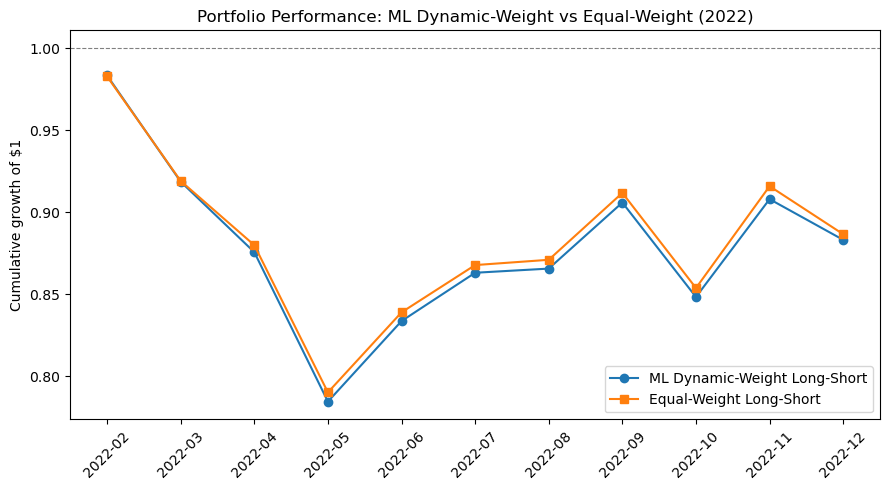

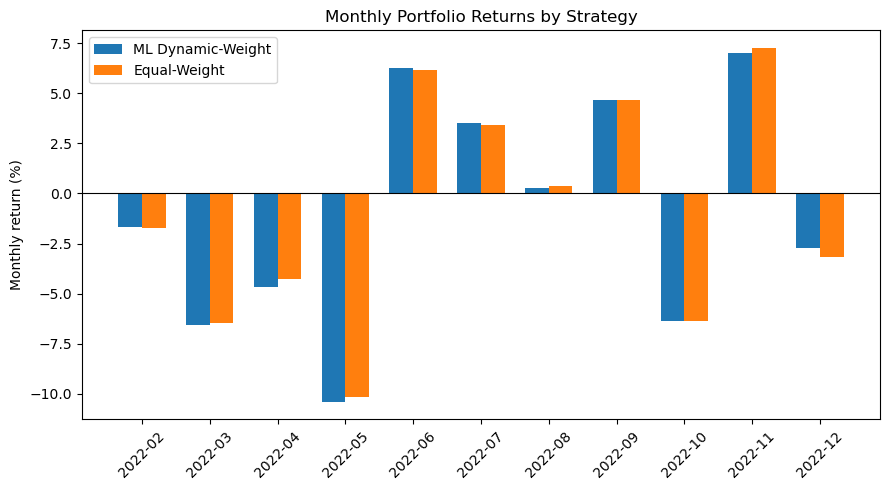

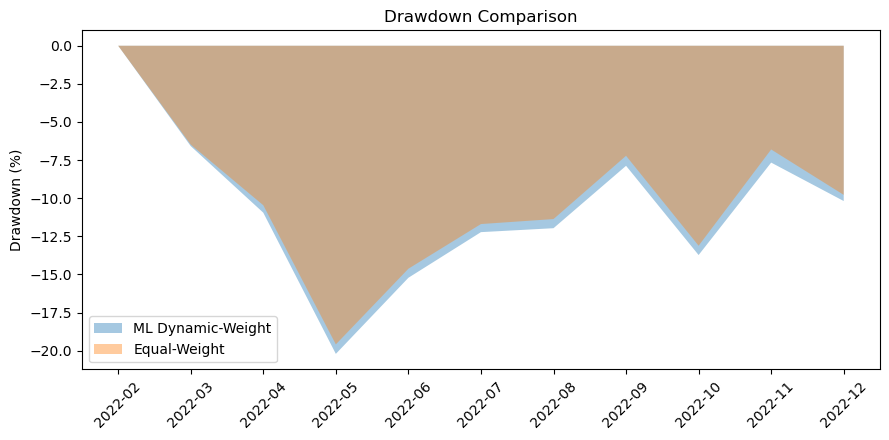

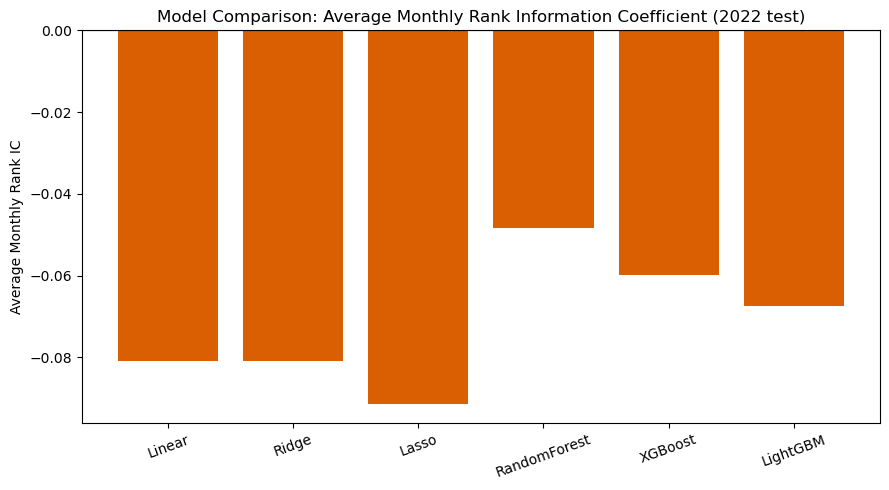

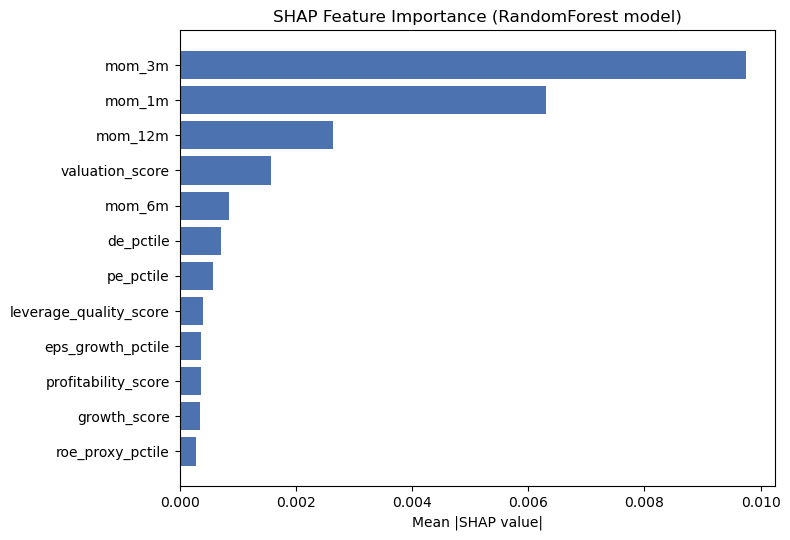

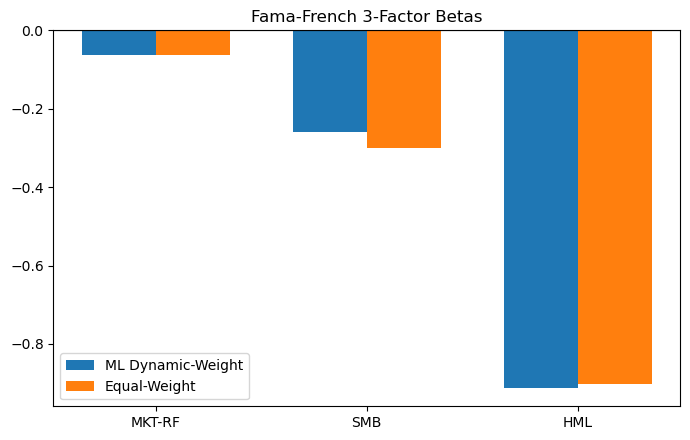

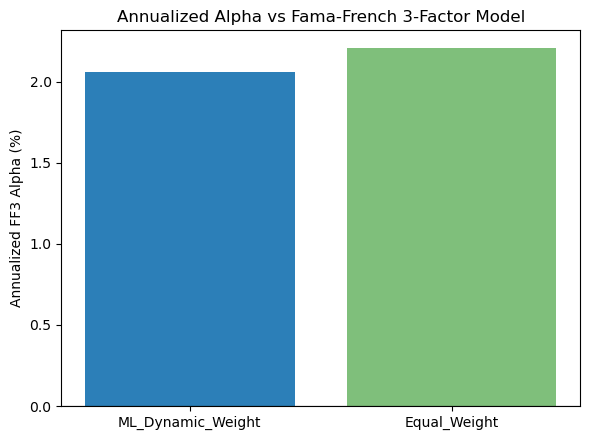

charts saved to outputs/charts
['ff3_betas.png', 'model_comparison_ic.png', 'cumulative_returns.png', 'alpha_comparison.png', 'monthly_returns_bar.png', 'drawdown.png', 'shap_importance.png']


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

OUT = "outputs/charts"
os.makedirs(OUT, exist_ok=True)

port = pd.read_csv("outputs/portfolio_with_ff3.csv")
port["month"] = port["month"].astype(str)

# 1. Cumulative return chart
cum_dyn = (1 + port["dynamic_return"]).cumprod()
cum_eq = (1 + port["equal_weight_return"]).cumprod()
plt.figure(figsize=(9, 5))
plt.plot(port["month"], cum_dyn, marker="o", label="ML Dynamic-Weight Long-Short")
plt.plot(port["month"], cum_eq, marker="s", label="Equal-Weight Long-Short")
plt.axhline(1.0, color="grey", linewidth=0.8, linestyle="--")
plt.xticks(rotation=45)
plt.ylabel("Cumulative growth of $1")
plt.title("Portfolio Performance: ML Dynamic-Weight vs Equal-Weight (2022)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/cumulative_returns.png", dpi=150)
plt.show()
plt.close()

# 2. Monthly returns bar comparison
plt.figure(figsize=(9, 5))
x = np.arange(len(port))
w = 0.35
plt.bar(x - w/2, port["dynamic_return"] * 100, width=w, label="ML Dynamic-Weight")
plt.bar(x + w/2, port["equal_weight_return"] * 100, width=w, label="Equal-Weight")
plt.xticks(x, port["month"], rotation=45)
plt.ylabel("Monthly return (%)")
plt.title("Monthly Portfolio Returns by Strategy")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/monthly_returns_bar.png", dpi=150)
plt.show()
plt.close()

# 3. Drawdown chart
running_max_dyn = np.maximum.accumulate(cum_dyn)
dd_dyn = cum_dyn / running_max_dyn - 1
running_max_eq = np.maximum.accumulate(cum_eq)
dd_eq = cum_eq / running_max_eq - 1
plt.figure(figsize=(9, 4.5))
plt.fill_between(port["month"], dd_dyn * 100, 0, alpha=0.4, label="ML Dynamic-Weight")
plt.fill_between(port["month"], dd_eq * 100, 0, alpha=0.4, label="Equal-Weight")
plt.xticks(rotation=45)
plt.ylabel("Drawdown (%)")
plt.title("Drawdown Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/drawdown.png", dpi=150)
plt.show()
plt.close()

# 4. Model comparison (Avg Rank IC / RMSE)
with open("outputs/model_comparison.json") as f:
    mc = json.load(f)
models = list(mc.keys())
ic_vals = [mc[m]["Avg_Rank_IC"] for m in models]

fig, ax1 = plt.subplots(figsize=(9, 5))
colors = ["#2c7fb8" if v >= 0 else "#d95f02" for v in ic_vals]
ax1.bar(models, ic_vals, color=colors)
ax1.set_ylabel("Average Monthly Rank IC")
ax1.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=20)
plt.title("Model Comparison: Average Monthly Rank Information Coefficient (2022 test)")
plt.tight_layout()
plt.savefig(f"{OUT}/model_comparison_ic.png", dpi=150)
plt.show()
plt.close()

# 5. SHAP feature importance
shap_imp = pd.read_csv("outputs/shap_feature_importance.csv")
plt.figure(figsize=(8, 5.5))
plt.barh(shap_imp["feature"][::-1], shap_imp["mean_abs_shap"][::-1], color="#4C72B0")
plt.xlabel("Mean |SHAP value|")
with open("outputs/shap_model_name.json") as f:
    shap_model_name = json.load(f)["shap_model"]
plt.title(f"SHAP Feature Importance ({shap_model_name} model)")
plt.tight_layout()
plt.savefig(f"{OUT}/shap_importance.png", dpi=150)
plt.show()
plt.close()

# 6. FF3 betas comparison
with open("outputs/ff3_alpha_results.json") as f:
    ff3 = json.load(f)
labels = ["beta_MKT_RF", "beta_SMB", "beta_HML"]
dyn_vals = [ff3["ML_Dynamic_Weight"][l] for l in labels]
eq_vals = [ff3["Equal_Weight"][l] for l in labels]
x = np.arange(len(labels))
plt.figure(figsize=(7, 4.5))
plt.bar(x - 0.175, dyn_vals, width=0.35, label="ML Dynamic-Weight")
plt.bar(x + 0.175, eq_vals, width=0.35, label="Equal-Weight")
plt.xticks(x, ["MKT-RF", "SMB", "HML"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Fama-French 3-Factor Betas")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/ff3_betas.png", dpi=150)
plt.show()
plt.close()

# 7. Alpha comparison
labels2 = ["ML_Dynamic_Weight", "Equal_Weight"]
alpha_ann = [ff3[l]["alpha_annualized"] * 100 for l in labels2]
plt.figure(figsize=(6, 4.5))
plt.bar(labels2, alpha_ann, color=["#2c7fb8", "#7fbf7b"])
plt.ylabel("Annualized FF3 Alpha (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Annualized Alpha vs Fama-French 3-Factor Model")
plt.tight_layout()
plt.savefig(f"{OUT}/alpha_comparison.png", dpi=150)
plt.show()
plt.close()

print("charts saved to", OUT)
print(os.listdir(OUT))